# EasyOCR demo - from a sample image to a database row

This notebook mirrors the flow of the **OCR Data Scanning Tool** step by step:

1. create a sample image with known text (no webcam needed),
2. run EasyOCR on it and inspect the raw output,
3. draw bounding boxes with OpenCV,
4. reuse the project's own `OCREngine` / preprocessing / drawing helpers,
5. see how the confidence threshold changes what is kept,
6. store the detections through the project's repository layer.

**Requirements:** run it with the project's virtual environment as the kernel
(`pip install -r requirements-dev.txt`, then `python -m ipykernel install --user --name ocr-scanner`).
The first EasyOCR call downloads ~100 MB of models into `~/.EasyOCR`.

In [1]:
import sys
import warnings
from pathlib import Path

# PyTorch emits deprecation notices from inside EasyOCR; they are not actionable here.
warnings.filterwarnings("ignore", category=UserWarning, module="torch")
warnings.filterwarnings("ignore", category=DeprecationWarning)

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))

import cv2
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image, ImageDraw, ImageFont

%matplotlib inline
print("Project root:", PROJECT_ROOT)

Project root: /Users/sunny/Apsit/Ocr-Scan


## 1. A sample image with known text

We draw two lines of text with Pillow so the expected answer is known in advance.

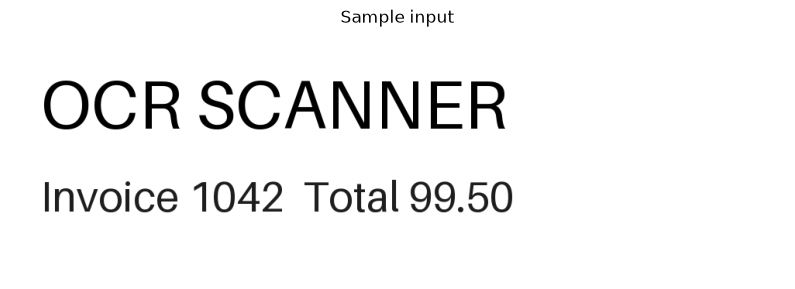

shape: (320, 1000, 3) dtype: uint8


In [2]:
image = Image.new("RGB", (1000, 320), "white")
draw = ImageDraw.Draw(image)
font_big = ImageFont.load_default(size=88)
font_small = ImageFont.load_default(size=54)
draw.text((40, 40), "OCR SCANNER", fill="black", font=font_big)
draw.text((40, 180), "Invoice 1042  Total 99.50", fill=(30, 30, 30), font=font_small)

plt.figure(figsize=(10, 3.5))
plt.imshow(image)
plt.axis("off")
plt.title("Sample input")
plt.show()

rgb = np.array(image)          # PIL -> numpy (RGB)
bgr = rgb[:, :, ::-1].copy()   # OpenCV works in BGR
print("shape:", bgr.shape, "dtype:", bgr.dtype)

## 2. Run EasyOCR directly

`easyocr.Reader` loads the detection (CRAFT) and recognition models. `gpu=False`
keeps everything on the CPU; pass `gpu=True` on a CUDA machine.

In [3]:
import easyocr

reader = easyocr.Reader(["en"], gpu=False, verbose=False)
raw = reader.readtext(rgb)

print(f"{len(raw)} detections\n")
print(f"{'text':<28} {'confidence':>10}   bbox (4 corner points)")
for bbox, text, conf in raw:
    corners = [(int(x), int(y)) for x, y in bbox]
    print(f"{text:<28} {conf:>10.3f}   {corners}")

3 detections

text                         confidence   bbox (4 corner points)
OCR SCANNER                       0.780   [(39, 53), (651, 53), (651, 139), (39, 139)]
Invoice 1042                      1.000   [(36, 188), (360, 188), (360, 244), (36, 244)]
Total 99.50                       0.948   [(376, 188), (658, 188), (658, 244), (376, 244)]


Each entry is a tuple `(bbox, text, confidence)`:

- `bbox` - four `[x, y]` corner points (top-left, top-right, bottom-right, bottom-left),
- `text` - the recognised string,
- `confidence` - a 0..1 score from the recognition model.

## 3. Draw the detections with OpenCV

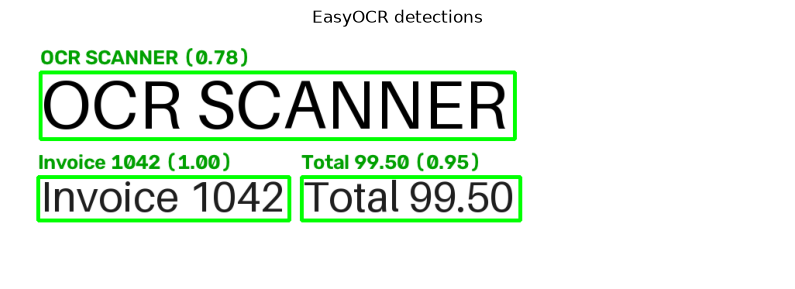

In [4]:
annotated = bgr.copy()
for bbox, text, conf in raw:
    pts = np.array(bbox, dtype=np.int32).reshape(-1, 1, 2)
    cv2.polylines(annotated, [pts], isClosed=True, color=(0, 255, 0), thickness=3)
    x, y = pts[:, 0, 0].min(), pts[:, 0, 1].min()
    cv2.putText(annotated, f"{text} ({conf:.2f})", (int(x), int(y) - 10),
                cv2.FONT_HERSHEY_SIMPLEX, 0.9, (0, 160, 0), 2, cv2.LINE_AA)

plt.figure(figsize=(10, 3.5))
plt.imshow(annotated[:, :, ::-1])   # BGR -> RGB for matplotlib
plt.axis("off")
plt.title("EasyOCR detections")
plt.show()

## 4. The same thing through the project's modules

The desktop app wraps EasyOCR in `core.ocr_engine.OCREngine` (lazy loading,
typed results, friendly errors) and keeps preprocessing + drawing in `core.detector`.

'OCR SCANNER'                  confidence=0.780  bbox=[[39, 53], [651, 53], [651, 139], [39, 139]]
'Invoice 1042'                 confidence=1.000  bbox=[[36, 188], [360, 188], [360, 244], [36, 244]]
'Total 99.50'                  confidence=0.948  bbox=[[376, 188], [658, 188], [658, 244], [376, 244]]


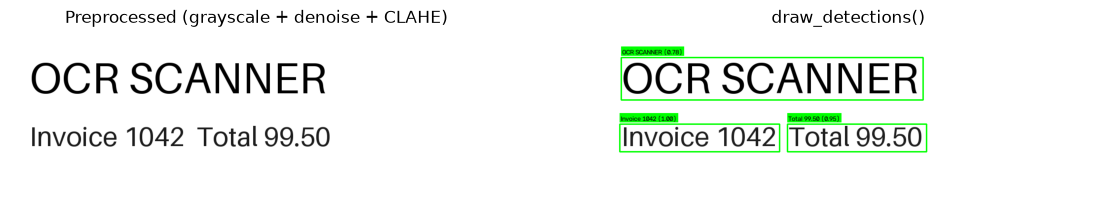

In [5]:
from core.detector import PreprocessOptions, draw_detections, preprocess_frame
from core.ocr_engine import OCREngine

engine = OCREngine(["en"], gpu="false")
engine.warm_up()                          # in the app this happens on a background thread
results = engine.detect(bgr, min_confidence=0.4)
for r in results:
    print(f"{r.text!r:<30} confidence={r.confidence:.3f}  bbox={r.bbox}")

processed, scale = preprocess_frame(bgr, PreprocessOptions(denoise=True, clahe=True))
fig, axes = plt.subplots(1, 2, figsize=(14, 3.5))
axes[0].imshow(processed, cmap="gray"); axes[0].set_title("Preprocessed (grayscale + denoise + CLAHE)")
axes[1].imshow(draw_detections(bgr, results)[:, :, ::-1]); axes[1].set_title("draw_detections()")
for ax in axes:
    ax.axis("off")
plt.show()

## 5. Confidence threshold

The app has a slider (default 0.4). Lower values keep more (noisier) detections.

In [6]:
all_results = engine.detect(bgr, min_confidence=0.0)
for threshold in (0.0, 0.2, 0.4, 0.6, 0.8, 0.95):
    kept = [r.text for r in all_results if r.confidence >= threshold]
    print(f"threshold {threshold:.2f}: {len(kept):>2} kept -> {kept}")

threshold 0.00:  3 kept -> ['OCR SCANNER', 'Invoice 1042', 'Total 99.50']
threshold 0.20:  3 kept -> ['OCR SCANNER', 'Invoice 1042', 'Total 99.50']
threshold 0.40:  3 kept -> ['OCR SCANNER', 'Invoice 1042', 'Total 99.50']
threshold 0.60:  3 kept -> ['OCR SCANNER', 'Invoice 1042', 'Total 99.50']
threshold 0.80:  2 kept -> ['Invoice 1042', 'Total 99.50']
threshold 0.95:  1 kept -> ['Invoice 1042']


## 6. Store the detections

The app writes to MySQL and falls back to SQLite when MySQL is unavailable. Both
backends implement the same `ScanRepository` interface, so the demo uses the
SQLite one to stay self-contained.

In [7]:
from datetime import datetime

from database.models import ScanRecord
from database.sqlite_repository import SQLiteScanRepository

repo = SQLiteScanRepository(PROJECT_ROOT / "data" / "demo_notebook.sqlite3")
session_id = repo.create_session(datetime.now())
now = datetime.now()
ids = repo.insert_scans([
    ScanRecord(None, session_id, r.text, r.confidence, r.bbox, None, "en", now) for r in results
])
repo.end_session(session_id, datetime.now(), len(ids))

print("inserted ids:", ids)
for row in repo.fetch_scans(limit=5):
    print(f"#{row.id}  {row.created_at:%H:%M:%S}  {row.confidence:.2f}  {row.detected_text}")
print("search 'invoice' ->", [r.detected_text for r in repo.search_scans("invoice")])
repo.close()

inserted ids: [4, 5, 6]
#6  21:20:08  0.95  Total 99.50
#5  21:20:08  1.00  Invoice 1042
#4  21:20:08  0.78  OCR SCANNER
#3  21:12:37  0.95  Total 99.50
#2  21:12:37  1.00  Invoice 1042
search 'invoice' -> ['Invoice 1042', 'Invoice 1042']


## Next steps

- Run the desktop app: `python main.py` (press **L** to launch the camera, **S** to scan).
- Add languages with `OCR_LANGUAGES=en,hi` in `.env` (EasyOCR downloads the extra model).
- Everything above is covered by the test-suite: `pytest -q`.